# Compute percolation paths

## Introduction
In this tutorial, we illustrate how to compute percolation paths in a crystalline material using mofography.
Computing percolation is important for a variety of applications including, 
- calculating the Pore Limiting Diameter (PLD) of a material
- determining the accessibility of a pocket, subject to a certain probe size
- diffusion related applications.

However, computing percolation paths is highly non-trivial in periodic materials. There is quite a bit of existing theory on doing this using grids, however, mofography already abstracts this grid into a pore graph, which means we can use path finding on graphs to compute percolation paths. This will be orders of magnitude faster than grid-based methods. However, the the number of all possible paths between a pair of nodes increases exponentially with the number of nodes, hence, this approach alone is greatly limiting. Hence, mofography uses a combination of two types of pathfinding algorithms as an approximation to find all the relevant paths for most applications. By relevant, we mean that paths that are the shortest in most cases, geometrically unique basis based on the types of pockets they connect, and the one that gives us the pore limiting dia. In a nutshell, 
- For small unit cells, all simple paths between all pairs of nodes on the opposite faces of the unit cell will give us the percolation paths.
- For larger unit cells, we use a combination of Dijkstra's algorithm to find the shortest paths (which are usually the straight channel paths), usually contain the PLD. 
- Note that when we compute paths in any direction, say, 'a', we included the periodic connectivity in the other two directions, 'b' and 'c' to ensure that we are not missing any paths that are periodic in the other two directions. While looking for percolation in one direction, the molecules are allowed to go out of the unit cell in the other two directions, and then come back in. 
- We also need keep track of the internal and periodic windows along each of the paths, as these are central to determining the accessibility of the pockets.

## Contents of this tutorial
- The usual steps, read in the structure -> distance grid -> regions, maxima -> pbc -> pore graph -> store everything on rag
- Test computation of percolation paths for the given mask_thickness
- show the percolated paths as a dataframe
- filter percolated paths inaccessible to a probe of a certain size
- plot the percolation paths on the structure
- in some materials, the set mask_thickness may not be enough to find any paths if all the windows are smaller than this, so we need to iteratively reduce the mask_thickness until we find some paths. There is a functino to do this in mofography, and we will illustrate how to use it here.

## Note
- This tutorial assumes that you have already read the tutorial up to the point of computing the pore graph. If not, please refer to the previous tutorials if anything is unclear. 
- we are still working on validating the PLD calculations, if something doesn't quite match with Zeo++ or other codes, please be patient, we'll fix it in a couple of days. 

## Imports

In [1]:
import numpy as np 
import os , sys
from pathlib import Path

import dask
from dask import delayed
from dask.distributed import progress, Client 

path_to_mgr = Path('../../../mofography_general/mofography')
sys.path.append(str(path_to_mgr))
import mofography as mgr

from ase.io import read, write
import plotly.graph_objects as go

## Read in random CIF from the examples folder

In [2]:
path_to_cif  = Path('../examples/TestCIFs/NU-1000_S1.cif')
mat_atoms = read(path_to_cif)

## Compute everything up to the pore graph and store everything 

In [3]:
dgrid = mgr.dgrid_from_atoms_cpu(mat_atoms, spacing=0.5)
regions, maxima = mgr.regions_from_dgrid(dgrid, mask_thickness=0.5 )
connections = mgr.connections_from_regions_and_dgrid(regions, dgrid, maxima, mat_atoms)
maxima_radii = dgrid[tuple(maxima.T)]
pbc_groups = mgr.apply_pbc(regions, maxima, maxima_radii, mat_atoms, return_conn=True)
rag = mgr.rag_from_connections(connections, maxima)
rag = mgr.add_maxima_to_rag(rag, maxima, maxima_radii, dgrid.shape, mat_atoms)
rag = mgr.add_pbc_to_rag(rag, pbc_groups=pbc_groups)
rag.graph['dgrid'] = dgrid
rag.graph['ase_atoms'] = mat_atoms
rag.graph['connections'] = connections
rag.graph['regions'] = regions
rag.graph['maxima']=maxima

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\utils\__init__.py:62: FutureWarning: Please use atoms.cell.cellpar() instead
  warnings.warn(warning)
c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography_general\mofography\docs\..\..\..\mofography_general\mofography\mofography\compute.py:382: UserWarning: Some maxima excluded as they fell inside the mask_thickness
  warnings.warn('Some maxima excluded as they fell inside the mask_thickness')
ic| regions_to_check: array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
                             18])
ic| len(outer): 18
c:\Users\Public\anaconda3\envs\test\lib\site-packages\numpy\core\shape_base.py:121: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  ary = a

## Compute percolation paths

Now we have everything needed to compute the percolation paths. If anything up to this point is unclear, please refer to the basic tutorials. Ok, in the code below, you'll notice the path_jump_cutoff parameter, this one limits the maximum length (number of edges) of the paths detected by the all possible paths part of the code. If set to None, it will set a number based on the size of the pore graph. Also, note that, although you cannot see it, this paths detection is based on all the distance and regions grids calculated and stored in the previous cell. So, if you change the mask_thickness in the regions segmentation, you will get different paths. Also, there could be a lot of paths detected for even a relatively big pore graph.

In [4]:
paths, path_windows, path_lengths = mgr.get_percolated_paths_on_rag(rag, path_jump_cutoff=None)

For direction  0
Dijkstra paths are computed for direction 0
Computing simple paths for direction 0


  0%|          | 0/3 [00:00<?, ?it/s]

100%|██████████| 3/3 [00:02<00:00,  1.00it/s]


For direction  1
Dijkstra paths are computed for direction 1
Computing simple paths for direction 1


100%|██████████| 3/3 [00:02<00:00,  1.00it/s]


For direction  2
Dijkstra paths are computed for direction 2
Computing simple paths for direction 2


100%|██████████| 6/6 [00:04<00:00,  1.44it/s]


Now, let's use the built-in function to show these detected paths as a pandas dataframe

In [5]:
mgr.show_percolated_paths_as_df(paths, path_windows, path_lengths)

,paths,path_windows,path_lengths
0,"[1, 1]","[5.350078563690186, 5.27008436203003]",0
1,"[2, 2]","[5.7629673957824705, 5.458671379089355]",0
2,"[17, 17]","[5.762994575500488, 5.4586999893188475]",0
3,"[18, 18]","[4.851957302093506, 4.779248218536377]",0
3108,"[4, 1]","[2.5237693637847896, 5.27008436203003]",1
...,...,...,...
5590,"[12, 18, 16, 15, 17]","[0.9033359183490185, 2.98123850221634, 2.08731...",4
5596,"[12, 18, 16, 17, 15]","[2.702353543151203, 2.98123850221634, 2.087312...",4
5598,"[12, 18, 16, 3, 1]","[2.98123850221634, 2.7660360145568847, 2.72057...",4
5600,"[12, 18, 16, 3, 2]","[2.98123850221634, 2.7660360145568847, 2.72057...",4


you can also filter out the paths that are inaccessible to a particular probe size, meaning all the paths with at least one window smaller than the probe size will be removed. This is done using the filter_percolation_paths function. The probe size is in Angstroms. 

So that looks like this: 

In [6]:
filtered_paths, filtered_path_windows, filtered_path_lengths= mgr.filter_percolated_paths(paths, path_windows, path_lengths, probe_size=1.5)
mgr.show_percolated_paths_as_df(filtered_paths, filtered_path_windows, filtered_path_lengths)

,paths,path_windows,path_lengths
0,"[1, 1]","[5.350078563690186, 5.27008436203003]",0
1,"[2, 2]","[5.7629673957824705, 5.458671379089355]",0
2,"[17, 17]","[5.762994575500488, 5.4586999893188475]",0
3,"[18, 18]","[4.851957302093506, 4.779248218536377]",0
1452,"[4, 1]","[2.5237693637847896, 5.27008436203003]",1
...,...,...,...
3073,"[12, 18, 11, 14, 15]","[2.9585334990902887, 2.6053859838771816, 1.951...",4
3086,"[12, 18, 15, 1, 7]","[2.0791225260742183, 2.0457323121756157, 2.605...",4
3104,"[12, 18, 16, 17, 15]","[2.702353543151203, 2.98123850221634, 2.087312...",4
3106,"[12, 18, 16, 3, 1]","[2.98123850221634, 2.7660360145568847, 2.72057...",4


We can use the built-in plot_paths function to generate traces to overlay the paths on the regions segmentation and the pore structure. Let's visualize.

Note that since usually there is a large number of paths, it might be beneficial to find 'unique' paths. which in this context could be finding paths that are non isormorphic, subject to the types of the pockets they connect. 

First let's detect the pocket types like before.

In [7]:
from skimage.measure import regionprops
props = regionprops(rag.graph['regions'])
rag = mgr.add_psd_to_rag_with_pbc(rag,props, pbc_groups, bins=100, ase_atoms=mat_atoms, shape=dgrid.shape) 

In [8]:
filtered_paths = [list(l) for l in filtered_paths]

In [9]:
paths_list = mgr.find_isomorphic_path_groups(filtered_paths[:100], rag)
# [np.unique(p) for p in paths_list ]

c:\Users\Public\anaconda3\envs\test\lib\site-packages\sklearn\cluster\_agglomerative.py:1006: FutureWarning: Attribute `affinity` was deprecated in version 1.2 and will be removed in 1.4. Use `metric` instead
  warnings.warn(


In [10]:
unique_paths = [list(t) for p in paths_list for t in set(tuple(u) for u in p)]

c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography_general\mofography\docs\..\..\..\mofography_general\mofography\mofography\visualize.py:175: FutureWarning: arrays to stack must be passed as a "sequence" type such as list or tuple. Support for non-sequence iterables such as generators is deprecated as of NumPy 1.16 and will raise an error in the future.
  coordinates= np.vstack(map(maxima_dict.get, path))


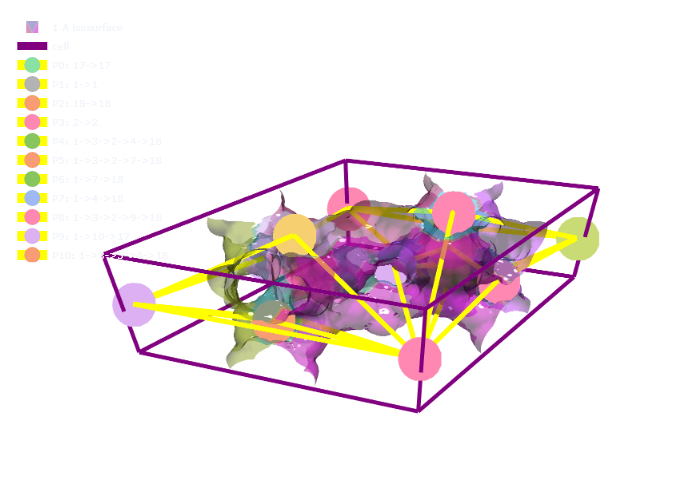

In [11]:
surface_trace = mgr.plot_surface_dgrid(dgrid, isovalue=1, ase_atoms = mat_atoms, region_labels=regions, stylize=True, opacity=0.5)
cell_trace = mgr.plot_cell(mat_atoms)

path_traces = mgr.plot_paths(rag,unique_paths, colorscale='Pastel')

fig = go.Figure(data=[surface_trace, cell_trace]+path_traces, layout=mgr.epic_layout)
fig.show(renderer='png')

## Iterative determination of percolation and PLD
For some of the materials, the set mask_thickness may not be enough to find any paths if all the windows are smaller than this, so we need to iteratively reduce the mask_thickness until we find some paths. There is a function to do this in mofography, and using it is quite simple. 

In [12]:
mgr.get_pld_for_rag(rag)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\utils\__init__.py:62: FutureWarning:

Please use atoms.cell.cellpar() instead



Number of atoms in the supercell: 558
No need to make supercell
- Constructing pore graph
pore graph constructed
pB applied
- Computing percolated paths
path jump cutoff is  None
For direction  0
Dijkstra paths are computed for direction 0
Computing simple paths for direction 0


  0%|          | 0/3 [00:00<?, ?it/s]

100%|██████████| 3/3 [00:02<00:00,  1.02it/s]


For direction  1
Dijkstra paths are computed for direction 1
Computing simple paths for direction 1


100%|██████████| 3/3 [00:02<00:00,  1.02it/s]


For direction  2
Dijkstra paths are computed for direction 2
Computing simple paths for direction 2


100%|██████████| 6/6 [00:04<00:00,  1.43it/s]


5.4586999893188475

In [14]:
def get_percolated_paths_on_rag_paralell(rag, minimum_overlap_fraction=0.5, wall_cells=6, path_jump_cutoff=None):
    import networkx as nx
    import mofography as mgr
    import numpy as np
    from icecream import ic
    import copy
    import pandas as pd 
    import more_itertools
    from time import time
    import dask
    from dask.diagnostics import ProgressBar
    time0 = time()
    keys_to_check = ['regions', 'connections', 'ase_atoms']

    for key in keys_to_check:
        if key not in rag.graph.keys():
            raise ValueError(f"'{key}' is not in rag.graph.keys(). Please compute and add it first to the rag under the graph dictionary like this: rag.graph['{key}'] = {key}.")
    regions = rag.graph['regions']
    mat_atoms = rag.graph['ase_atoms']
    connections = rag.graph['connections']
    shape = regions.shape
    map_list = []
    paths = []
    path_windows= []
    path_lengths = []
    periodic_connections  = [c for c in connections if c[1] and c[2]=='periodic']
    
    if path_jump_cutoff is None:
        # path_jump_cutoff = np.max([int(np.cbrt(np.max(regions))), 4])
        ranges = [(0, 10), (10, 40), (40, float('inf'))]
        outputs = [8, 4, 2]

        # Create the dictionary
        path_jump_cutoff = pd.cut([rag.number_of_nodes()], bins=[r[0] for r in ranges] + [float('inf')], labels=outputs)[0]


    if len(periodic_connections) > 0:
        periodic_windows_exist = True
        periodic_connected_regions= np.array([pc[0] for pc in periodic_connections]) # * just the indices of the connected regions, just needed to make sure that we don't miss any periodic windows between the same regions
        periodic_window_coords = np.vstack([c[3] for c in periodic_connections])
        periodic_window_fractional_coords = mgr.get_fractional_coordinates(periodic_window_coords, mat_atoms)

        # * we need to know which wall these windwos are on, round values close to 0 to 0 and values close to 1 to 1
        #* we will use this as an additional check when getting the correct window diameters 
        periodic_window_walls  = np.where(periodic_window_fractional_coords < 0.03, 0, np.where(periodic_window_fractional_coords > 0.97, 1, periodic_window_fractional_coords))
    


        # * this bit is for creating a master list of where the periodic windows exist
        dist_thresh = 0.03

        # * let's make an array to store the wall window location
        regions_wall_windows = np.full((regions.max(), 7), np.NaN)
        regions_wall_windows[:, 0] = np.arange(1, regions.max() + 1)



        #* get the periodic window radii
        pws_window_radii = [w for c in connections if c[1] and c[2]=='periodic' for w in c[4]]

        # * periodic windows occur in pairs, so let's just take the first entry in the regions list
        #* get region numbers and window coordinates
        pws_regions_coords = ([[c[0][0], w] for c in connections if c[1] and c[2]=='periodic' for w in c[3]])



        # wall_
        pws_flags = [] # * array to store the wall locatoin of the periodic windows
        # * now we have to find which wall the windwo belongs to 
        frac_coords= mgr.get_fractional_coordinates(np.vstack([p[1] for p in pws_regions_coords]), mat_atoms)

        for i in range(3):
            wall_mask = np.logical_or(frac_coords[:, i] < dist_thresh, frac_coords[:, i] > 1 - dist_thresh)
            wall_indices = np.where(wall_mask)[0]
            wall_directions = np.where(frac_coords[wall_indices, i] < dist_thresh, 0, 1)
            pws_flags.extend(zip(wall_indices, [i] * len(wall_indices), wall_directions)) # entries of type (R, a, w) where R is the region number, a is the wall direction 0, 1 or 2, and w is the wall index either 0 or 1
        pws_temp_list = [] # * make a list so that we can eliminate some windows if need be 
        
        #* for example, if the rregional maxima is on the wall, then don't consider windows on that wall in that direction (only). 
        #* if there are multiple windows for the same oregion on the same wall, take only the largest one

        # * now make the master array of which region and wall the periodic window exists
        for pwf in pws_flags:
            region_number = pws_regions_coords[pwf[0]][0] # get the region number from the list
            wall_index = 2*pwf[1] + pwf[2] + 1 # get the wall index , a=0:1, a=1:2, b=0:3, b=1:4, c=0:5, c=1:6 , 0 if for the region number
            # * note that a periodic window can be on multiple walls
            # regions_wall_windows[region_number][wall_index] = regions_pws[pwf[0]][1] # put the window coordinate in the right locatoin
            wall_window_radius = pws_window_radii[pwf[0]]
            # * the index will be the region_number - 1 
            
            pws_temp_list.append([region_number, wall_index, wall_window_radius])
        
        #* find rows with the same reigon_number and wall_index, keep the row with the largest window radius
        pws_temp_list = np.array(pws_temp_list)
        pws_temp_list = pws_temp_list[np.argsort(pws_temp_list[:,2])][::-1] # sort by window radius
        pws_temp_, pws_unique_indices = np.unique(pws_temp_list[:,[0,1]], axis=0,return_index=True) # remove duplicates
        pws_temp_list = pws_temp_list[pws_unique_indices] # * now we only keep the largest window radius for a given region number on the same wall
        
        for ptl in pws_temp_list:
            # print('ptl is ', ptl)
            regions_wall_windows[int(ptl[0]) -1 ][int(ptl[1])] = ptl[2] # regions_pws[pwf[0]][1] # put the window coordinate in the right locatoin

        # for c in connections:
    
    else:
        periodic_windows_exist = False
        periodic_connected_regions = []
        periodic_window_coords = []
        periodic_window_fractional_coords = []
        periodic_window_walls = []
        regions_wall_windows = np.full((regions.max(),7), np.NaN)
        regions_wall_windows[:,0] = np.arange(1, regions.max()+1)
    # * handle the single extending regions
    for a in [0,1,2]:
        # print(a)
        ic(a, 'Direction')
        # [] # * empty array to store all the paths in direction a
        # window_sizes[a] = [] # * empty array to store all the window sizes along all the paths in direction a
        
        llr = regions.take(indices=0 ,axis=a) #* left wall
        rrr = regions.take(indices=shape[a]-1 ,axis=a)  #* right wall
        corresponding_regions = np.unique(list(zip(llr.flatten(), rrr.flatten())),axis=0)
        

        # * remove rows that are all zero
        corresponding_regions = corresponding_regions[np.all(corresponding_regions!=0, axis=1)]
        ic(corresponding_regions, 'Map list for direction {}'.format(a))
        # print("For direction {} the corresponding regions are {}".format(a, corresponding_regions))
        map_list.append(corresponding_regions) # * add the corresponding regions to the map list for direction a
        
        # * find rows in which both the values are the same
        # * these are the regions that extend across the unit cell
        same_regions_indices = corresponding_regions[:,0]==corresponding_regions[:,1]
        if len(same_regions_indices) > 0:
            same_regions = corresponding_regions[same_regions_indices]

            # * find the size of the periodic windows attached to such regions 
            # * but these need to be the periodic window in the correct direction also, so we will use the periodic_window_walls array for additional check

            paths_a = []
            path_windows_a= []
            path_lengths_a = []
            for s in same_regions:
                windows_same_region = [c[4] for i, c in enumerate(periodic_connections) if np.all(c[0]==s) and (periodic_window_walls[i][a]==0 or periodic_window_walls[i][a]==1)]
                if len(windows_same_region) > 0:
                    path_windows_a.append(np.hstack(windows_same_region))
                    paths_a.append(s)
                    path_lengths_a.append(0)
        # print(paths_a, path_windows_a)
        
        
        

            #* for all the corresponding regions, if both of them are in the same periodic group, and connected in perpendicular direction, 
            # * then add an edge between them as with path_weight 0 as long as both the regions are not he same

            paths.append(paths_a)
            path_windows.append(path_windows_a)
            path_lengths.append(path_lengths_a)
    # * handle all the other end to end paths after adding pbc connections in perpendicular directions
    for a in [0,1,2]:
        # get teh mapping list for that direction
        corresponding_regions = map_list[a]
        # print('Looking for paths in direction:', a)
        # print('corresponding regions are ', corresponding_regions)
        rag_temp = copy.deepcopy(rag) #* make a copy of the rag
            
        #* add a property tot he edges called path_weight with value 1 for all internal edges
        nx.set_edge_attributes(rag_temp, 1, 'path_weight')

        ic(rag_temp.edges(data='window_info'), 'Edges in rag_temp initially')
        # map_list = map_list[a]
        
        # * now we will add all the periodic edges in the other two directions
        for j in [0,1,2]:
            if j != a: # * choose the other two directions
                left_wall = regions.take(indices=0 ,axis=j) #* left wall
                right_wall = regions.take(indices=shape[j]-1 ,axis=j)  #* right wall
                llf= left_wall.flatten()
                rrf= right_wall.flatten()

                #* now for teh regions mapped in j direction, we need to add periodic connections with path_weight 0
                corresponding_regions_j = map_list[j]

                #* we need the overlap fractions of regions in the correspondence list
                #* we will use this check also before adding the periodic connection
                if len(corresponding_regions_j) > 0:
                    reg_numbers = np.vstack([(k, v) for k,v in corresponding_regions_j])


                    #* let's compute and prnt percentage overlap between pairs of mapping regions
                    #* let's filter those connections with less thant 10% overlap
                    sumlist = [np.sum(llf==r[0]) for r in reg_numbers]
                    matching = [np.sum(np.logical_and(llf==r[0], rrf==r[1])) for r in reg_numbers] 
                    fractional_overlap = [m/s for m,s in zip(matching, sumlist)]

                    #* flags where there should be a left to right connection 
                    left_right = [f> minimum_overlap_fraction for f in fractional_overlap]

                    ic(a, 'Direction')
                    ic(j, 'Secondary direction')

                    # reg_numbers = reg_numbers[np.where([f > minimum_overlap_fraction for f in fractional_overlap])]
                    # print('left-right\n')
                    # print(list(zip(reg_numbers, fractional_overlap)))

                    # * backwards check

                    # #* let's compute and prnt percentage overlap between pairs of mapping regions
                    # #* let's filter those connections with less thant minimum overlap fraction
                    sumlist = [np.sum(rrf==r[1]) for r in reg_numbers]
                    matching = [np.sum(np.logical_and(llf==r[0], rrf==r[1])) for r in reg_numbers] 
                    fractional_overlap = [m/s for m,s in zip(matching, sumlist)]
                    
                    #* flags where there should be a right to left connection
                    right_left = [f> minimum_overlap_fraction for f in fractional_overlap]
                    
                    # print('right-left\n')
                    # print(list(zip(reg_numbers, fractional_overlap)))
                    # now let's combine the two flags
                    pick_these = np.logical_or(left_right, right_left)

                    reg_numbers = reg_numbers[pick_these]
                    ic(reg_numbers, 'Regions to add periodic connections between for secondary direction {}'.format(j))
          
                    for c in reg_numbers:
                        if c[0]!=c[1]:

                            if np.any([np.all([c[0], c[1]]==p)  or np.all([c[1], c[0]]==p) for p in periodic_connected_regions]):
                                rag_temp.add_edge(c[0], c[1], path_weight=1)
                            
                            # if there is a maxima at the wall, then the ppath weigth should be 0
                            else:                        
                                rag_temp.add_edge(c[0], c[1], path_weight=0)
                ic(rag_temp.edges(data='path_weight'), 'Edges in rag_temp after direction {}'.format(j))
        # print('a is ', a)
        # print('edges are ', rag_temp.edges(data='path_weight'))
        # these are all the paths
        paths_a_ = list(nx.all_pairs_dijkstra_path(rag_temp, weight='path_weight'))
        path_lengths_a_ = list(nx.all_pairs_dijkstra_path_length(rag_temp, weight='path_weight'))
        print('Dijkstra paths are computed for direction {}'.format(a))
        
        # print(rag_temp.edges(data=True))
        #* what are the paths connecting any region in column 0 in corresponding regions to 'any' region in column 1 in corresponding regions
        paths_a = []
        windows_a = []
        path_lengths_a = []

    #     #* now we need to find the windows along these paths, just get the window sizes when the path_weight of that edge is 1 else it is a periodic window between same regions
        # from igraph import Graph

        # # Convert your NetworkX graph to an iGraph graph
        # g = Graph.from_networkx(rag_temp)
        # @dask.delayed
        # def process_paths(llr, rrr, g, path_jump_cutoff, a, wall_cells, regions, regions_wall_windows, paths_a_, path_lengths_a_):
        #     results = []
        #     if llr != rrr:
        #         all_possible_paths = g.get_all_simple_paths(llr, to=rrr, cutoff=path_jump_cutoff)
        #         # process paths as before...
        #         for path in all_possible_paths:
        #             edges_to_select = list(more_itertools.pairwise(path))
        #             subgraph = rag_temp.edge_subgraph(edges_to_select)
        #             window_radii = [np.array([np.max(c[4])])  for e in subgraph.edges() for c in connections if c[1] and (np.all(c[0]==[e[0],e[1]]) or np.all(c[0]==[e[1],e[0]])) ]

        #             column_index = a*2+1
        #             if not np.isnan(regions_wall_windows[llr-1][column_index]) and (rag.nodes[llr]['maxima_indices'][a]>wall_cells):
        #                 window_radii.append(regions_wall_windows[llr-1][column_index])

        #             if not np.isnan(regions_wall_windows[rrr-1][column_index+1]) and (rag.nodes[rrr]['maxima_indices'][a] < regions.shape[a] - wall_cells):
        #                 window_radii.append(regions_wall_windows[rrr-1][column_index+1])

        #             edge_attrs = nx.get_edge_attributes(subgraph, 'path_weight')
        #             path_weight_sum = sum(edge_attrs.values())
        #             results.append((path, window_radii, path_weight_sum))

        #         if rrr in paths_a_[llr-1][1].keys():
        #             path_of_interest = paths_a_[llr-1][1][rrr]
        #             edges_to_select = list(more_itertools.pairwise(path_of_interest))
        #             subgraph = rag_temp.edge_subgraph(edges_to_select)
        #             window_radii = [np.array([np.max(c[4])])  for e in subgraph.edges() for c in connections if c[1] and (np.all(c[0]==[e[0],e[1]]) or np.all(c[0]==[e[1],e[0]])) ]

        #             column_index = a*2+1
        #             if not np.isnan(regions_wall_windows[llr-1][column_index]) and (rag.nodes[llr]['maxima_indices'][a]>wall_cells):
        #                 window_radii.append(regions_wall_windows[llr-1][column_index])

        #             if not np.isnan(regions_wall_windows[rrr-1][column_index+1]) and (rag.nodes[rrr]['maxima_indices'][a] < regions.shape[a] - wall_cells):
        #                 window_radii.append(regions_wall_windows[rrr-1][column_index+1])

        #             results.append((path_of_interest, window_radii, path_lengths_a_[llr-1][1][rrr]))
        #     return results


        @dask.delayed
        def process_paths(llr, rrr, rag_temp, path_jump_cutoff, a, wall_cells, regions, regions_wall_windows, paths_a_, path_lengths_a_):
            results = []
            if llr != rrr:
                all_possible_paths = nx.all_simple_paths(rag_temp, source =llr, target = rrr, cutoff=path_jump_cutoff)
                # print('All possible paths between {} and {} are {}'.format(llr, rrr, all_possible_paths))
                for path in all_possible_paths:
                    edges_to_select = list(more_itertools.pairwise(path))
                    subgraph = rag_temp.edge_subgraph(edges_to_select)
                    window_radii = [np.array([np.max(c[4])])  for e in subgraph.edges() for c in connections if c[1] and (np.all(c[0]==[e[0],e[1]]) or np.all(c[0]==[e[1],e[0]])) ]

                    column_index = a*2+1
                    if not np.isnan(regions_wall_windows[llr-1][column_index]) and (rag.nodes[llr]['maxima_indices'][a]>wall_cells):
                        window_radii.append(regions_wall_windows[llr-1][column_index])

                    if not np.isnan(regions_wall_windows[rrr-1][column_index+1]) and (rag.nodes[rrr]['maxima_indices'][a] < regions.shape[a] - wall_cells):
                        window_radii.append(regions_wall_windows[rrr-1][column_index+1])

                    edge_attrs = nx.get_edge_attributes(subgraph, 'path_weight')
                    path_weight_sum = sum(edge_attrs.values())
                    results.append((path, window_radii, path_weight_sum))

                if rrr in paths_a_[llr-1][1].keys():
                    path_of_interest = paths_a_[llr-1][1][rrr]
                    edges_to_select = list(more_itertools.pairwise(path_of_interest))
                    subgraph = rag_temp.edge_subgraph(edges_to_select)
                    window_radii = [np.array([np.max(c[4])])  for e in subgraph.edges() for c in connections if c[1] and (np.all(c[0]==[e[0],e[1]]) or np.all(c[0]==[e[1],e[0]])) ]

                    column_index = a*2+1
                    if not np.isnan(regions_wall_windows[llr-1][column_index]) and (rag.nodes[llr]['maxima_indices'][a]>wall_cells):
                        window_radii.append(regions_wall_windows[llr-1][column_index])

                    if not np.isnan(regions_wall_windows[rrr-1][column_index+1]) and (rag.nodes[rrr]['maxima_indices'][a] < regions.shape[a] - wall_cells):
                        window_radii.append(regions_wall_windows[rrr-1][column_index+1])

                    results.append((path_of_interest, window_radii, path_lengths_a_[llr-1][1][rrr]))
            return results

        tasks = [process_paths(llr, rrr, rag_temp, path_jump_cutoff, a, wall_cells, regions, regions_wall_windows, paths_a_, path_lengths_a_) for llr in corresponding_regions[:,0] for rrr in corresponding_regions[:,1]]
        with ProgressBar():
            results = dask.compute(*tasks)
        print('All paths are computed', results)
        for result in results:
            for path, window_radii, path_length in result:
                paths_a.append(path)
                windows_a.append(window_radii)
                path_lengths_a.append(path_length)
        print(paths_a, windows_a, path_lengths_a)
        paths.append(paths_a)
        path_windows.append(windows_a)
        path_lengths.append(path_lengths_a)
    #* let's do some reshaping
    path_windows_list = [np.hstack(pws).tolist() if len(pws)>0 else [] for pws_ in path_windows for pws in pws_]
    paths_list = [pws for pws_ in paths for pws in pws_]
    path_lengths_list = [pws for pws_ in path_lengths for pws in pws_]
    

    # paths_ = [p for pw_a in paths for p in pw_a ]
    # path_windows_ = [pw for pw_a in path_windows for pw in pw_a]
    # path_lengths_= [pw for pw_a in  path_lengths for pw in pw_a]

    # # print('Paths before clean up' )
    # # print(show_percolated_paths_as_df(paths_, path_windows_, path_lengths_))

    # # * remove paths with path weight 0 and the nodes are not the same
    paths_final = []
    path_windows_final = []
    path_lengths_final = []

    # for p, pw, pl in zip(paths_, path_windows_, path_lengths_):
    for p, pw, pl in zip(paths_list, path_windows_list, path_lengths_list):
        if pl > 0 :
            paths_final.append(p)
            path_windows_final.append(pw)
            path_lengths_final.append(pl)
        else:
            # path should only have 2 nodes and both should be the same
            if (len(p)==2 and p[0]==p[1]) or len(pw) > 0:
                paths_final.append(p)
                path_windows_final.append(pw)
                path_lengths_final.append(pl)

    return paths_final, path_windows_final, path_lengths_final

In [78]:
# get_percolated_paths_on_rag_paralell(rag, path_jump_cutoff=2)

In [79]:
# get_pld_for_rag(rag)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\utils\__init__.py:62: FutureWarning:

Please use atoms.cell.cellpar() instead



Number of atoms in the supercell: 558
No need to make supercell
- Constructing pore graph
pore graph constructed
pB applied
- Computing percolated paths
path jump cutoff is  None
For direction  0
Dijkstra paths are computed for direction 0
Computing simple paths for direction 0


100%|██████████| 3/3 [00:02<00:00,  1.15it/s]


For direction  1
Dijkstra paths are computed for direction 1
Computing simple paths for direction 1


100%|██████████| 3/3 [00:02<00:00,  1.14it/s]


For direction  2
Dijkstra paths are computed for direction 2
Computing simple paths for direction 2


100%|██████████| 6/6 [00:03<00:00,  1.62it/s]


5.4586999893188475